# 1. Data: sources, cohorts, endpoint and split

This notebook prepares everything that comes before the model. We download each data source and record its version, build the two patient cohorts, define the outcome we predict, fix the list of candidate genes and set aside a test set. Every later notebook starts from the files written here.

Patient-level data stays in the `data/` folder, which git ignores. The outputs below are counts, summaries and plots.

## Settings

Every choice of this notebook is named in the second cell below, with its reason beside it. The first cell only loads the libraries and locates the folders.

In [1]:
import hashlib, json, subprocess, sys
from concurrent.futures import ThreadPoolExecutor
from datetime import date
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split
from sksurv.nonparametric import kaplan_meier_estimator

REPO = Path(subprocess.run(["git", "rev-parse", "--show-toplevel"], capture_output=True, text=True, check=True).stdout.strip())
DATA = REPO / "data"                    # downloads and patient-level tables; ignored by git
RESULTS = REPO / "results" / "01_data"  # aggregate tables only; tracked by git
RESULTS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", None)  # some tables hold long text such as checksums; show it in full
HTTP = requests.Session()               # one session, so that connections to a server are reused

In [2]:
GDC_API = "https://api.gdc.cancer.gov"  # NCI Genomic Data Commons
GDC_PAGE_SIZE = 10000                   # larger than any file list we ask for, so one page holds the whole answer
TCGA_PROJECT = "TCGA-BRCA"
CDR_FILE_ID = "1b5f413e-a8d1-4d10-92eb-7c4ae739ed81"  # the TCGA-CDR workbook linked on the GDC PanCanAtlas page
SUPPLEMENT_NAME = "nationwidechildrens.org_clinical_patient_brca.txt"  # patient table of the clinical supplement
DATAHUB = "cBioPortal/datahub/dca75cb3f32b82d54a6f78bf0a6323e5b975aca1/public/brca_metabric"  # commit pinned on 2026-09-30
HTTP_TIMEOUT = (10, 600)                # seconds to wait for a connection, then for data; the short first value
                                        # moves on quickly when one address of a server does not answer
DOWNLOAD_THREADS = 8                    # parallel downloads; the expression source has about a thousand small files
CHUNK_BYTES = 1 << 20                   # files are read and written in pieces of 1 MiB, so none is held in memory whole
PRIMARY_TUMOUR_CODE = "01"              # TCGA sample-type code of a primary solid tumour
DAYS_PER_YEAR = 365.25                  # average length of a year, leap years included
DAYS_PER_MONTH = DAYS_PER_YEAR / 12     # METABRIC reports follow-up in months
CLASS_CUTS_DAYS = [365, 1095, 1825]     # 1, 3 and 5 years: the class borders of the earlier pipeline
TEST_FRACTION = 0.2                     # share of TCGA patients locked away as the test set
SPLIT_SEED = 0                          # fixed so that the split is the same in every run

## Downloading with a record

Four helpers serve every source. For each source we first write a manifest: the list of its files, the checksum the source publishes for each one, the version and the date. A checksum is a short fingerprint of a file's content. Files are downloaded only when they are missing, so a second run downloads nothing, and every file is compared with its checksum in every run.

In [3]:
def file_hash(path, algorithm):
    digest = hashlib.new(algorithm)
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(CHUNK_BYTES), b""):
            digest.update(chunk)
    return digest.hexdigest()


def download(url, path):
    """Fetch url into path unless the file is already there. Return True when a download happened."""
    if path.exists():
        return False
    partial = path.with_name(path.name + ".part")  # a half-written file must never look complete
    with HTTP.get(url, stream=True, timeout=HTTP_TIMEOUT) as response:
        response.raise_for_status()
        with open(partial, "wb") as handle:
            for chunk in response.iter_content(CHUNK_BYTES):
                handle.write(chunk)
    partial.rename(path)
    return True

In [4]:
def write_manifest(folder, source_version, files):
    folder.mkdir(parents=True, exist_ok=True)
    manifest = {"version": source_version, "retrieved_on": date.today().isoformat(), "files": files}
    (folder / "manifest.json").write_text(json.dumps(manifest, indent=1))


def fetch_and_verify(folder, files):
    """Download the missing files, then count the files that match their recorded checksum."""
    with ThreadPoolExecutor(DOWNLOAD_THREADS) as pool:
        downloaded = sum(pool.map(lambda f: download(f["url"], folder / f["name"]), files))
        verified = sum(pool.map(lambda f: file_hash(folder / f["name"], f["checksum_type"]) == f["checksum"], files))
    return {"downloaded in this run": downloaded, "checksum correct": verified, "files": len(files)}

## Source 1: TCGA-BRCA gene expression

The expression data come from the NCI Genomic Data Commons (GDC). We ask the GDC for every open-access STAR gene-count file of the project (STAR is the program that aligns the sequencing reads). Each file holds, for one tissue sample, the read count and the TPM value of every gene. TPM (transcripts per million) is a count scaled for gene length and sequencing depth, so that samples are comparable. The answer is saved as the manifest, with the data release the GDC reports. The output counts the listed files by sample type.

In [5]:
def gdc_list_files(filters, fields):
    """Ask the GDC files index for the files that match every filter."""
    conditions = [{"op": "=", "content": {"field": field, "value": value}} for field, value in filters.items()]
    body = {"filters": {"op": "and", "content": conditions}, "fields": ",".join(fields), "size": GDC_PAGE_SIZE}
    answer = HTTP.post(f"{GDC_API}/files", json=body, timeout=HTTP_TIMEOUT).json()["data"]
    assert answer["pagination"]["total"] == len(answer["hits"]), "the file list must arrive complete, not as a first page"
    return answer["hits"]


def gdc_release():
    return HTTP.get(f"{GDC_API}/status", timeout=HTTP_TIMEOUT).json()["data_release"]


star_dir = DATA / "raw" / "gdc_star_counts"
if not (star_dir / "manifest.json").exists():
    hits = gdc_list_files({"cases.project.project_id": TCGA_PROJECT, "data_type": "Gene Expression Quantification",
                           "analysis.workflow_type": "STAR - Counts", "access": "open"},
                          ["file_id", "file_name", "md5sum", "cases.submitter_id", "cases.samples.sample_type",
                           "associated_entities.entity_submitter_id"])
    files = [{"name": h["file_name"], "url": f"{GDC_API}/data/{h['file_id']}", "checksum_type": "md5", "checksum": h["md5sum"],
              "patient": h["cases"][0]["submitter_id"], "sample_type": h["cases"][0]["samples"][0]["sample_type"],
              "aliquot": h["associated_entities"][0]["entity_submitter_id"]} for h in hits]
    write_manifest(star_dir, gdc_release(), sorted(files, key=lambda f: f["aliquot"]))
star_listing = pd.DataFrame(json.loads((star_dir / "manifest.json").read_text())["files"])
star_listing["sample_type"].value_counts().rename("files").to_frame()

,files
sample_type,
Primary Tumor,1111
Solid Tissue Normal,113
Metastatic,7


## One primary tumour sample per patient

We keep primary tumour samples only, and exactly one per patient. Normal tissue and metastases differ biologically from the primary tumour, and a patient with two samples would count twice. When a patient has several primary tumour aliquots (portions of tissue sequenced separately), we keep the one whose barcode, the TCGA identifier of the aliquot, sorts first. This fixed rule does not look at the data.

In [6]:
primary = star_listing[star_listing["sample_type"] == "Primary Tumor"]
tcga_samples = primary.sort_values("aliquot").groupby("patient").head(1).set_index("patient").sort_index()
patients_with_several = int((primary.groupby("patient").size() > 1).sum())
display(Markdown(f"{len(primary)} primary tumour files belong to {len(tcga_samples)} patients. "
                 f"{patients_with_several} patients have more than one file; for each of them the first barcode is kept."))

1111 primary tumour files belong to 1095 patients. 11 patients have more than one file; for each of them the first barcode is kept.

In [7]:
# The aliquot barcode carries the sample type in characters 14 and 15, independently of the GDC field used above.
assert (tcga_samples["aliquot"].str[13:15] == PRIMARY_TUMOUR_CODE).all(), "a selected sample is not a primary tumour"
assert tcga_samples.index.is_unique, "a patient has more than one selected sample"

Only the selected files are downloaded, several at a time, and each is compared with the MD5 checksum the GDC lists for it. The output says how many files were downloaded in this run and how many passed the check. The same cell stores the description of the source for the table further down.

In [8]:
SOURCES = {"TCGA-BRCA gene expression": {
    "folder": star_dir,
    "what it is": "STAR gene counts and TPM per Ensembl gene (GENCODE v36), one file per tissue sample",
    "where from": f"{GDC_API}/files with project {TCGA_PROJECT}, Gene Expression Quantification, STAR - Counts, open access; "
                  f"each file from {GDC_API}/data/[file id]",
    "terms of use": "Open access, no login. GDC open data fall under the NIH Genomic Data Sharing policy: do not attempt to "
                    "identify participants, and acknowledge the data set and the repository. TCGA asks for an acknowledgement "
                    "of the TCGA Research Network (https://www.cancer.gov/tcga).",
    "citation": "Heath et al., Nat Genet 2021, doi:10.1038/s41588-021-00791-5 (GDC); "
                "The Cancer Genome Atlas Network, Nature 2012, doi:10.1038/nature11412 (TCGA-BRCA)",
    "source checksum": "MD5 listed in the GDC files index",
    "check": fetch_and_verify(star_dir, tcga_samples.to_dict("records"))}}
SOURCES["TCGA-BRCA gene expression"]["check"]

{'downloaded in this run': 0, 'checksum correct': 1095, 'files': 1095}

## Source 2: TCGA outcomes

The outcomes come from the TCGA Pan-Cancer Clinical Data Resource (CDR), a curated table of follow-up for all TCGA patients published with Liu et al. (2018). The GDC distributes it as one workbook on its PanCanAtlas publication page and sends the MD5 checksum of the file in the response header, which we record as the source checksum.

In [9]:
cdr_dir = DATA / "raw" / "tcga_cdr"
cdr_url = f"{GDC_API}/data/{CDR_FILE_ID}"
if not (cdr_dir / "manifest.json").exists():
    with HTTP.get(cdr_url, stream=True, timeout=HTTP_TIMEOUT) as response:  # headers only; the body is fetched below
        cdr_md5 = response.headers["Content-MD5"]
    write_manifest(cdr_dir, "Supplemental Table S1 of Liu et al. 2018, GDC file " + CDR_FILE_ID,
                   [{"name": "TCGA-CDR-SupplementalTableS1.xlsx", "url": cdr_url, "checksum_type": "md5", "checksum": cdr_md5}])
SOURCES["TCGA outcomes (CDR)"] = {
    "folder": cdr_dir,
    "what it is": "Curated clinical table of all TCGA cancer types with four outcome endpoints (OS, DSS, DFI, PFI)",
    "where from": cdr_url + ", linked from https://gdc.cancer.gov/about-data/publications/pancanatlas",
    "terms of use": "Open access at the GDC under the same policy as the expression files. "
                    "The article is open access under CC BY-NC-ND 4.0.",
    "citation": "Liu et al., Cell 2018, doi:10.1016/j.cell.2018.02.052",
    "source checksum": "MD5 sent by the GDC in the Content-MD5 response header",
    "check": fetch_and_verify(cdr_dir, json.loads((cdr_dir / "manifest.json").read_text())["files"])}
SOURCES["TCGA outcomes (CDR)"]["check"]

{'downloaded in this run': 0, 'checksum correct': 1, 'files': 1}

## Source 3: TCGA receptor status

The CDR does not carry the receptor status of the tumour (ER, PR and HER2), which are standard clinical variables in breast cancer. They are in the clinical supplement of TCGA-BRCA at the GDC, a tab-separated table with one row per patient. We look the file up by name, so its checksum comes from the GDC index.

In [10]:
supplement_dir = DATA / "raw" / "gdc_clinical_supplement"
if not (supplement_dir / "manifest.json").exists():
    # The unpacking fails unless exactly one file has this name.
    hit, = gdc_list_files({"cases.project.project_id": TCGA_PROJECT, "file_name": SUPPLEMENT_NAME, "access": "open"},
                          ["file_id", "file_name", "md5sum"])
    write_manifest(supplement_dir, gdc_release(), [{"name": hit["file_name"], "url": f"{GDC_API}/data/{hit['file_id']}",
                                                    "checksum_type": "md5", "checksum": hit["md5sum"]}])
SOURCES["TCGA-BRCA clinical supplement"] = {
    "folder": supplement_dir,
    "what it is": "Patient table of the clinical supplement (BCR Biotab), used for ER, PR and HER2 status",
    "where from": f"{GDC_API}/files with project {TCGA_PROJECT} and file name {SUPPLEMENT_NAME}; "
                  f"the file from {GDC_API}/data/[file id]",
    "terms of use": "Open access at the GDC under the same policy as the expression files.",
    "citation": "The Cancer Genome Atlas Network, Nature 2012, doi:10.1038/nature11412; "
                "Heath et al., Nat Genet 2021, doi:10.1038/s41588-021-00791-5 (GDC)",
    "source checksum": "MD5 listed in the GDC files index",
    "check": fetch_and_verify(supplement_dir, json.loads((supplement_dir / "manifest.json").read_text())["files"])}
SOURCES["TCGA-BRCA clinical supplement"]["check"]

{'downloaded in this run': 0, 'checksum correct': 1, 'files': 1}

## Source 4: METABRIC

METABRIC is the independent cohort: breast tumours collected in the United Kingdom and Canada and measured on a microarray instead of by sequencing. We take it from the cBioPortal datahub on GitHub, pinned to one commit so that the files cannot change under us. The datahub stores large files through Git LFS, whose pointer file records the SHA-256 checksum of the real file; we use it as the source checksum.

In [11]:
metabric_dir = DATA / "raw" / "metabric"
if not (metabric_dir / "manifest.json").exists():
    files = []
    for name in ["data_clinical_patient.txt", "data_clinical_sample.txt", "data_mrna_illumina_microarray.txt"]:
        pointer = HTTP.get(f"https://raw.githubusercontent.com/{DATAHUB}/{name}", timeout=HTTP_TIMEOUT).text
        files.append({"name": name, "url": f"https://media.githubusercontent.com/media/{DATAHUB}/{name}",
                      "checksum_type": "sha256", "checksum": pointer.split("oid sha256:")[1].split()[0]})
    write_manifest(metabric_dir, "cBioPortal datahub commit " + DATAHUB.split("/")[2], files)
SOURCES["METABRIC"] = {
    "folder": metabric_dir,
    "what it is": "Clinical patient table, clinical sample table and Illumina HT-12 v3 expression matrix (log2 intensity) "
                  "of the study brca_metabric",
    "where from": "https://media.githubusercontent.com/media/ " + DATAHUB.replace(DATAHUB.split("/")[2], " [commit] ") + "/ [file name]",
    "terms of use": "Open Database License (ODbL) 1.0, stated in the LICENSE file of the study folder: free to share and "
                    "adapt with attribution; derived data sets stay open under the same licence.",
    "citation": "Curtis et al., Nature 2012, doi:10.1038/nature10983; Pereira et al., Nat Commun 2016, doi:10.1038/ncomms11479 "
                "(METABRIC); Cerami et al., Cancer Discov 2012, doi:10.1158/2159-8290.CD-12-0095 (cBioPortal)",
    "source checksum": "SHA-256 recorded in the Git LFS pointer file",
    "check": fetch_and_verify(metabric_dir, json.loads((metabric_dir / "manifest.json").read_text())["files"])}
SOURCES["METABRIC"]["check"]

{'downloaded in this run': 0, 'checksum correct': 3, 'files': 3}

In [12]:
# A file that differs from the checksum its source publishes is not the file the source describes.
assert all(s["check"]["checksum correct"] == s["check"]["files"] for s in SOURCES.values()), "a downloaded file fails its checksum"

## Data sources

The table gathers what a reader needs to obtain the same files: what each source is, where it comes from, its version, the day we retrieved it, its terms of use as the source states them, and the paper to cite. The last rows come from the local record: where the checksum of each file comes from, how many files passed it, and the SHA-256 of the manifest, which identifies the exact file list.

In [13]:
def describe_source(name, source):
    manifest = json.loads((source["folder"] / "manifest.json").read_text())
    return {"source": name, "what it is": source["what it is"], "where from": source["where from"],
            "version": manifest["version"], "retrieved on": manifest["retrieved_on"],
            "terms of use": source["terms of use"], "citation": source["citation"],
            "source checksum": source["source checksum"], "files checked": source["check"]["checksum correct"],
            "manifest sha256": file_hash(source["folder"] / "manifest.json", "sha256")}


sources_table = pd.DataFrame([describe_source(name, source) for name, source in SOURCES.items()]).set_index("source")
sources_table.to_csv(RESULTS / "sources.csv")
# A Markdown table wraps long sentences; a data frame would cut or stretch them.
# A long checksum or commit gets a line break after 32 characters, so that four columns fit a page.
shown = sources_table.astype(str).apply(lambda column: column.str.replace("([0-9a-f]{32})(?=[0-9a-f])", r"\1<br>", regex=True))
lines = ["| | " + " | ".join(shown.index) + " |", "|---" * (len(shown) + 1) + "|"]
lines += [f"| {field} | " + " | ".join(shown[field]) + " |" for field in shown.columns]
display(Markdown("\n".join(lines)))

| | TCGA-BRCA gene expression | TCGA outcomes (CDR) | TCGA-BRCA clinical supplement | METABRIC |
|---|---|---|---|---|
| what it is | STAR gene counts and TPM per Ensembl gene (GENCODE v36), one file per tissue sample | Curated clinical table of all TCGA cancer types with four outcome endpoints (OS, DSS, DFI, PFI) | Patient table of the clinical supplement (BCR Biotab), used for ER, PR and HER2 status | Clinical patient table, clinical sample table and Illumina HT-12 v3 expression matrix (log2 intensity) of the study brca_metabric |
| where from | https://api.gdc.cancer.gov/files with project TCGA-BRCA, Gene Expression Quantification, STAR - Counts, open access; each file from https://api.gdc.cancer.gov/data/[file id] | https://api.gdc.cancer.gov/data/1b5f413e-a8d1-4d10-92eb-7c4ae739ed81, linked from https://gdc.cancer.gov/about-data/publications/pancanatlas | https://api.gdc.cancer.gov/files with project TCGA-BRCA and file name nationwidechildrens.org_clinical_patient_brca.txt; the file from https://api.gdc.cancer.gov/data/[file id] | https://media.githubusercontent.com/media/ cBioPortal/datahub/ [commit] /public/brca_metabric/ [file name] |
| version | Data Release 46.0 - August 10, 2026 | Supplemental Table S1 of Liu et al. 2018, GDC file 1b5f413e-a8d1-4d10-92eb-7c4ae739ed81 | Data Release 46.0 - August 10, 2026 | cBioPortal datahub commit dca75cb3f32b82d54a6f78bf0a6323e5<br>b975aca1 |
| retrieved on | 2026-09-30 | 2026-09-30 | 2026-09-30 | 2026-09-30 |
| terms of use | Open access, no login. GDC open data fall under the NIH Genomic Data Sharing policy: do not attempt to identify participants, and acknowledge the data set and the repository. TCGA asks for an acknowledgement of the TCGA Research Network (https://www.cancer.gov/tcga). | Open access at the GDC under the same policy as the expression files. The article is open access under CC BY-NC-ND 4.0. | Open access at the GDC under the same policy as the expression files. | Open Database License (ODbL) 1.0, stated in the LICENSE file of the study folder: free to share and adapt with attribution; derived data sets stay open under the same licence. |
| citation | Heath et al., Nat Genet 2021, doi:10.1038/s41588-021-00791-5 (GDC); The Cancer Genome Atlas Network, Nature 2012, doi:10.1038/nature11412 (TCGA-BRCA) | Liu et al., Cell 2018, doi:10.1016/j.cell.2018.02.052 | The Cancer Genome Atlas Network, Nature 2012, doi:10.1038/nature11412; Heath et al., Nat Genet 2021, doi:10.1038/s41588-021-00791-5 (GDC) | Curtis et al., Nature 2012, doi:10.1038/nature10983; Pereira et al., Nat Commun 2016, doi:10.1038/ncomms11479 (METABRIC); Cerami et al., Cancer Discov 2012, doi:10.1158/2159-8290.CD-12-0095 (cBioPortal) |
| source checksum | MD5 listed in the GDC files index | MD5 sent by the GDC in the Content-MD5 response header | MD5 listed in the GDC files index | SHA-256 recorded in the Git LFS pointer file |
| files checked | 1095 | 1 | 1 | 3 |
| manifest sha256 | a4dc598e3a6b33a25b41f5b5a0333468<br>c40608ccafcebcb8af691953b372ea57 | 7aa992b9354a6cfb216484cc1cec50cf<br>4ea21182e9a7ee4d877723464f6dcfeb | 5a46021ee4c699a7b97111b409baff87<br>6143ef8ff5ebd68156198b3faffff7fa | 8b70a304d2b057c343ee233f23e45972<br>654eed7cb5343625c49f197a0be7bf15 |

## TCGA-BRCA cohort

The cohort starts from the TCGA-BRCA patients in the CDR and applies three rules in order: the patient has a primary tumour RNA-seq file, the overall survival (OS) status and time are recorded, and the time is above zero. A time of zero means the patient was not followed after diagnosis and carries no survival information. No missing outcome is filled in: such patients are excluded and counted. The table shows the patients and deaths left after each rule.

In [14]:
def apply_rules(table, start_label, rules):
    """Apply the rules in order. Return the rows that remain and the counts after each rule."""
    counts = [{"rule": start_label, "patients": len(table), "deaths": int(table["os_event"].sum())}]
    for label, keep in rules:
        table = table[keep(table)]
        counts.append({"rule": label, "patients": len(table), "deaths": int(table["os_event"].sum())})
    return table.sort_index(), pd.DataFrame(counts).set_index("rule")


cdr = pd.read_excel(cdr_dir / "TCGA-CDR-SupplementalTableS1.xlsx", sheet_name="TCGA-CDR", index_col="bcr_patient_barcode")
cdr = cdr[cdr["type"] == "BRCA"].rename(columns={"OS": "os_event", "OS.time": "os_days"})
tcga, tcga_counts = apply_rules(cdr, "TCGA-BRCA patients in the CDR", [
    ("with a primary tumour RNA-seq file", lambda t: t.index.isin(tcga_samples.index)),
    ("with OS status and OS time recorded", lambda t: t["os_event"].notna() & t["os_days"].notna()),
    ("with OS time above 0", lambda t: t["os_days"] > 0)])
tcga_counts.to_csv(RESULTS / "cohort_tcga.csv")
tcga_counts

,patients,deaths
rule,,
TCGA-BRCA patients in the CDR,1097,151
with a primary tumour RNA-seq file,1094,151
with OS status and OS time recorded,1093,151
with OS time above 0,1080,151


Two groups inside the cohort deserve a mention. The rules fixed for this notebook keep both; removing them is a separate decision. The redaction flag of the CDR marks cases that TCGA annotated as problematic, for example an uncertain sample identity.

In [15]:
display(Markdown(f"RNA-seq patients without a CDR record, and so without an outcome: {int((~tcga_samples.index.isin(cdr.index)).sum())}. "
                 f"Men in the cohort: {int((tcga['gender'] == 'MALE').sum())}. "
                 f"Cohort patients carrying the redaction flag: {int(tcga['Redaction'].notna().sum())}."))

RNA-seq patients without a CDR record, and so without an outcome: 1. Men in the cohort: 12. Cohort patients carrying the redaction flag: 4.

## METABRIC cohort

The same rules apply to METABRIC: the patient has a column in the expression matrix, the OS status and time are recorded, and the time is above zero. A recorded tumour stage is not required. Follow-up is given in months and converted to days. METABRIC outcomes are only counted in this notebook; no model sees them before the external evaluation.

In [16]:
metabric_patients = pd.read_csv(metabric_dir / "data_clinical_patient.txt", sep="\t", comment="#", index_col="PATIENT_ID")
metabric_samples = pd.read_csv(metabric_dir / "data_clinical_sample.txt", sep="\t", comment="#", index_col="PATIENT_ID")
metabric_expression = pd.read_csv(metabric_dir / "data_mrna_illumina_microarray.txt", sep="\t")
metabric_patients["os_event"] = metabric_patients["OS_STATUS"].map({"0:LIVING": 0, "1:DECEASED": 1})
metabric_patients["os_days"] = metabric_patients["OS_MONTHS"] * DAYS_PER_MONTH
metabric, metabric_counts = apply_rules(metabric_patients, "METABRIC patients in the clinical table", [
    ("with a column in the expression matrix", lambda t: t.index.isin(metabric_expression.columns)),
    ("with OS status and OS time recorded", lambda t: t["os_event"].notna() & t["os_days"].notna()),
    ("with OS time above 0", lambda t: t["os_days"] > 0)])
metabric_counts.to_csv(RESULTS / "cohort_metabric.csv")
metabric_counts

,patients,deaths
rule,,
METABRIC patients in the clinical table,2509,1144
with a column in the expression matrix,1980,1143
with OS status and OS time recorded,1980,1143
with OS time above 0,1979,1143


In [17]:
# The expression columns are named by sample; joining them to patients is only valid if each patient has one sample of the same name.
assert (metabric_samples["SAMPLE_ID"] == metabric_samples.index).all(), "a METABRIC sample is not named like its patient"
assert metabric_samples.index.is_unique and metabric_patients.index.is_unique, "a METABRIC patient appears twice"

## Clinical covariates

Five clinical variables are kept for both cohorts: age at diagnosis, tumour stage, and the status of three receptors (ER, PR and HER2) that guide breast cancer treatment. Stage is reduced to its main level. A receptor status is positive or negative; a test that was not done, or that gave an equivocal or indeterminate result, becomes the level unknown. Nobody is dropped for a missing covariate, and a missing age stays missing here. Resolving equivocal HER2 results with the second test (FISH) is left out.

In [18]:
def receptor_status(status):
    """Keep positive and negative; every other value, missing ones included, becomes 'unknown'."""
    status = status.str.lower().replace({"positve": "positive"})  # the METABRIC table spells it this way
    return status.where(status.isin(["positive", "negative"]), "unknown")


# Lines 2 and 3 of the file repeat the header in two other vocabularies and are skipped.
supplement = pd.read_csv(supplement_dir / SUPPLEMENT_NAME, sep="\t", skiprows=[1, 2], index_col="bcr_patient_barcode")
supplement = supplement.reindex(tcga.index)  # a patient absent from the supplement gets missing values, hence 'unknown'
tcga_clinical = pd.DataFrame({
    "os_days": tcga["os_days"], "os_event": tcga["os_event"].astype(int),
    "age": tcga["age_at_initial_pathologic_diagnosis"],
    "stage": tcga["ajcc_pathologic_tumor_stage"].str.extract(r"^Stage (IV|III|II|I)", expand=False).fillna("unknown"),
    "er": receptor_status(supplement["er_status_by_ihc"]),
    "pr": receptor_status(supplement["pr_status_by_ihc"]),
    "her2": receptor_status(supplement["her2_status_by_ihc"])})
metabric_sample = metabric_samples.loc[metabric.index]
metabric_clinical = pd.DataFrame({
    "os_days": metabric["os_days"], "os_event": metabric["os_event"].astype(int),
    "age": metabric["AGE_AT_DIAGNOSIS"],
    "stage": metabric_sample["TUMOR_STAGE"].map({0: "0", 1: "I", 2: "II", 3: "III", 4: "IV"}).fillna("unknown"),
    "er": receptor_status(metabric["ER_IHC"]),
    "pr": receptor_status(metabric_sample["PR_STATUS"]),
    "her2": receptor_status(metabric_sample["HER2_STATUS"])})

The table counts the patients at each level. In TCGA the three receptor values are measured by immunohistochemistry (IHC). In METABRIC only ER is stated to be by IHC; the file does not say how its PR and HER2 status were measured. A level that only one cohort uses will need a decision before the external evaluation.

In [19]:
covariate_names = ["stage", "er", "pr", "her2"]
covariate_table = pd.DataFrame({
    "TCGA-BRCA": pd.concat({name: tcga_clinical[name].value_counts() for name in covariate_names}),
    "METABRIC": pd.concat({name: metabric_clinical[name].value_counts() for name in covariate_names})}).fillna(0).astype(int)
covariate_table.index.names = ["covariate", "level"]
covariate_table.to_csv(RESULTS / "covariates.csv")
display(covariate_table)
display(Markdown(f"Median age at diagnosis: {tcga_clinical['age'].median():.0f} years in TCGA-BRCA and {metabric_clinical['age'].median():.0f} in METABRIC. "
                 f"Age is missing for {int(tcga_clinical['age'].isna().sum())} and {int(metabric_clinical['age'].isna().sum())} patients."))

TCGA-BRCA  METABRIC
covariate level                        
er        negative        237       439
          positive        795      1498
          unknown          48        42
her2      negative        555      1732
          positive        160       247
          unknown         365         0
pr        negative        339       939
          positive        690      1040
          unknown          51         0
stage     0                 0        12
          I               181       501
          II              610       825
          III             245       118
          IV               20        10
          unknown          24       513

Median age at diagnosis: 58 years in TCGA-BRCA and 62 in METABRIC. Age is missing for 0 and 0 patients.

## The endpoint: overall survival as time and event

The outcome is overall survival: the time from diagnosis to death from any cause. For a patient who was alive at the last contact we only know that survival is longer than the follow-up; such a record is called censored. We keep the outcome as two numbers per patient, the time in days and an event flag (1 for death, 0 for censored), and never turn it into a class. The table summarises both cohorts.

In [20]:
def outcome_summary(clinical):
    return {"patients": len(clinical), "deaths": int(clinical["os_event"].sum()),
            "censored (%)": round(100 * (1 - clinical["os_event"].mean()), 1),
            "median observed time (years)": round(clinical["os_days"].median() / DAYS_PER_YEAR, 1),
            "longest observed time (years)": round(clinical["os_days"].max() / DAYS_PER_YEAR, 1)}


outcome_table = pd.DataFrame([outcome_summary(tcga_clinical), outcome_summary(metabric_clinical)], index=["TCGA-BRCA", "METABRIC"])
outcome_table.to_csv(RESULTS / "outcome_summary.csv")
outcome_table

,patients,deaths,censored (%),median observed time (years),longest observed time (years)
TCGA-BRCA,1080,151,86.0,2.4,23.6
METABRIC,1979,1143,42.2,9.7,29.6


The Kaplan-Meier curve estimates, from censored data, the share of patients still alive at each time. The figure answers one question: how survival and the length of follow-up differ between the two cohorts. The shaded band is the 95% confidence interval; it widens where few patients remain under observation.

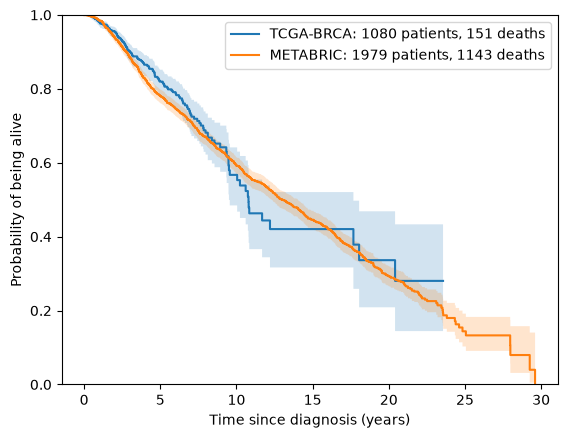

In [21]:
figure, axis = plt.subplots()
for name, clinical in [("TCGA-BRCA", tcga_clinical), ("METABRIC", metabric_clinical)]:
    years, alive, band = kaplan_meier_estimator(clinical["os_event"].astype(bool), clinical["os_days"] / DAYS_PER_YEAR,
                                                conf_type="log-log")
    axis.step(years, alive, where="post", label=f"{name}: {len(clinical)} patients, {clinical['os_event'].sum()} deaths")
    axis.fill_between(years, band[0], band[1], step="post", alpha=0.2)  # light shading keeps both curves visible
axis.set_xlabel("Time since diagnosis (years)")
axis.set_ylabel("Probability of being alive")
axis.set_ylim(0, 1)
axis.legend()
plt.show()

The CDR paper (Liu et al., 2018) advises caution with OS and DSS in breast cancer, because the follow-up of TCGA is short relative to the course of the disease, and recommends PFI and DFI. OS remains the working endpoint of this notebook. The table counts the events of every available endpoint among the cohort patients, so the cost of that choice is visible. DSS counts deaths from the disease, DFI a return of the disease after a disease-free period, and PFI any progression, return, or death from the disease.

In [22]:
endpoint_flags = {
    ("TCGA-BRCA", "OS: death from any cause"): tcga["os_event"],
    ("TCGA-BRCA", "DSS: death from the disease"): tcga["DSS"],
    ("TCGA-BRCA", "DFI: return after a disease-free period"): tcga["DFI"],
    ("TCGA-BRCA", "PFI: progression, return or death from the disease"): tcga["PFI"],
    ("METABRIC", "OS: death from any cause"): metabric["os_event"],
    ("METABRIC", "death from the disease"): (metabric["VITAL_STATUS"] == "Died of Disease").where(metabric["VITAL_STATUS"].notna()),
    ("METABRIC", "relapse"): metabric["RFS_STATUS"].map({"0:Not Recurred": 0, "1:Recurred": 1})}
endpoint_table = pd.DataFrame({key: {"patients with a value": int(flag.notna().sum()), "events": int(flag.sum())}
                               for key, flag in endpoint_flags.items()}).T
endpoint_table.index.names = ["cohort", "endpoint"]
endpoint_table.to_csv(RESULTS / "endpoints.csv")
endpoint_table

patients with a value  \
cohort    endpoint                                                                    
TCGA-BRCA OS: death from any cause                                             1080   
          DSS: death from the disease                                          1061   
          DFI: return after a disease-free period                               938   
          PFI: progression, return or death from the disease                   1080   
METABRIC  OS: death from any cause                                             1979   
          death from the disease                                               1978   
          relapse                                                              1978   

                                                              events  
cohort    endpoint                                                    
TCGA-BRCA OS: death from any cause                               151  
          DSS: death from the disease                             83  
          DFI: return after a disease-free period                 84  
          PFI: progression, return or death from the disease     145  
METABRIC  OS: death from any cause                              1143  
          death from the disease                                 646  
          relapse                                                803

## Survival classes of the earlier pipeline

The earlier pipeline replaced the outcome by four classes of OS time, cut at 1, 3 and 5 years, and used the class number as the target of gene selection and as the stratification key. The table bins our TCGA cohort the same way. A censored patient in a class did not die in that interval: the follow-up ended there. A class made mostly of censored patients describes how long patients were followed, not how long they lived. For this reason the rebuild uses no classes and keeps time and event.

In [23]:
class_labels = ["up to 1 year", "1 to 3 years", "3 to 5 years", "over 5 years"]
time_class = pd.cut(tcga_clinical["os_days"], bins=[0, *CLASS_CUTS_DAYS, np.inf], labels=class_labels)
class_table = tcga_clinical.groupby(time_class, observed=False)["os_event"].agg(patients="size", deaths="sum")
class_table["censored"] = class_table["patients"] - class_table["deaths"]
class_table["censored (%)"] = (100 * class_table["censored"] / class_table["patients"]).round(1)
class_table.index.name = "OS time"
class_table.to_csv(RESULTS / "survival_classes.csv")
display(class_table)
shortest = class_table.iloc[0]
display(Markdown(f"In the class {class_table.index[0]}, {shortest['censored']:.0f} of {shortest['patients']:.0f} patients "
                 f"({shortest['censored (%)']}%) are censored. They did not die within the year; their follow-up ended there."))

,patients,deaths,censored,censored (%)
OS time,,,,
up to 1 year,166,20,146,88.0
1 to 3 years,477,49,428,89.7
3 to 5 years,185,30,155,83.8
over 5 years,252,52,200,79.4


In the class up to 1 year, 146 of 166 patients (88.0%) are censored. They did not die within the year; their follow-up ended there.

## Expression matrices

We read the TPM column of every cohort patient's file into one matrix, patients by genes, and take log2(TPM + 1), the usual transform that compresses the wide range of expression values. It is applied to each value on its own. No step in this notebook looks across patients: filtering and scaling belong to the training folds of the next notebook. Genes are keyed by their Ensembl ID. The assert confirms that every file lists the same genes in the same order.

In [24]:
def read_star_file(name, columns):
    table = pd.read_csv(star_dir / name, sep="\t", comment="#", usecols=columns)
    return table[~table["gene_id"].str.startswith("N_")].reset_index(drop=True)  # the first four rows are mapping statistics, not genes


tcga_genes = read_star_file(tcga_samples["name"].iloc[0], ["gene_id", "gene_name", "gene_type"])
tpm, same_genes = {}, []
for patient, name in tcga_samples.loc[tcga.index, "name"].items():
    table = read_star_file(name, ["gene_id", "tpm_unstranded"])
    same_genes.append(table["gene_id"].equals(tcga_genes["gene_id"]))
    tpm[patient] = table["tpm_unstranded"].to_numpy()
tcga_expression = np.log2(pd.DataFrame(tpm, index=tcga_genes["gene_id"]).T + 1)
display(Markdown(f"TCGA-BRCA expression matrix: {tcga_expression.shape[0]} patients by {tcga_expression.shape[1]} genes. "
                 f"METABRIC expression matrix: {len(metabric)} cohort patients by {len(metabric_expression)} rows."))

TCGA-BRCA expression matrix: 1080 patients by 60660 genes. METABRIC expression matrix: 1979 cohort patients by 20603 rows.

In [25]:
# Columns of different files can only be stacked into one matrix if they describe the same genes in the same order.
assert all(same_genes), "an expression file lists different genes"
assert tcga_expression.notna().all().all(), "a TCGA expression value is missing"

## Candidate gene pool

A model trained on TCGA is later applied to METABRIC, so a gene is only usable if both platforms measure it. TCGA names genes by Ensembl ID and METABRIC by gene symbol, two naming systems for genes. We keep the genes whose symbol occurs exactly once in the TCGA gene list and exactly once in the METABRIC matrix, which makes the match one to one. The pool is decided from the two gene lists alone: no expression value and no outcome is used. The table shows what each matching step removes.

In [26]:
metabric_symbol_counts = metabric_expression["Hugo_Symbol"].value_counts()
once_in_tcga = ~tcga_genes["gene_name"].duplicated(keep=False)
in_metabric = tcga_genes["gene_name"].isin(metabric_symbol_counts.index)
once_in_metabric = tcga_genes["gene_name"].isin(metabric_symbol_counts[metabric_symbol_counts == 1].index)
steps = {"genes in the TCGA files": pd.Series(True, index=tcga_genes.index),
         "symbol occurs once in TCGA": once_in_tcga,
         "symbol is present in METABRIC": once_in_tcga & in_metabric,
         "symbol occurs once in METABRIC": once_in_tcga & once_in_metabric}
pool_steps = pd.DataFrame({"genes left": {label: int(keep.sum()) for label, keep in steps.items()}})
pool_steps["removed by this step"] = (-pool_steps["genes left"].diff()).fillna(0).astype(int)
gene_pool = tcga_genes[once_in_tcga & once_in_metabric].rename(columns={"gene_name": "symbol", "gene_type": "biotype"})
gene_pool.to_csv(RESULTS / "gene_pool.csv", index=False)
pool_steps.to_csv(RESULTS / "gene_pool_steps.csv")
display(pool_steps)
display(Markdown(f"The candidate pool holds {len(gene_pool)} genes; {(gene_pool['biotype'] == 'protein_coding').mean():.1%} of them are protein coding."))

,genes left,removed by this step
genes in the TCGA files,60660,0
symbol occurs once in TCGA,59317,1343
symbol is present in METABRIC,19405,39912
symbol occurs once in METABRIC,19211,194


The candidate pool holds 19211 genes; 93.7% of them are protein coding.

## One table per cohort

Each cohort becomes one table with a row per patient: the outcome, the five covariates and the expression of the pool genes. The METABRIC columns are renamed from symbol to Ensembl ID, so both tables share their column names. METABRIC values are log2 microarray intensities and stay as they are. The two platforms are on different scales, which the scaling inside the training folds has to handle later.

In [27]:
tcga_table = tcga_clinical.join(tcga_expression[gene_pool["gene_id"]])
metabric_pool = metabric_expression.set_index("Hugo_Symbol").loc[gene_pool["symbol"], metabric.index].T
metabric_pool.columns = gene_pool["gene_id"].to_numpy()
metabric_table = metabric_clinical.join(metabric_pool)
display(Markdown(f"TCGA-BRCA table: {tcga_table.shape[0]} patients by {tcga_table.shape[1]} columns. "
                 f"METABRIC table: {metabric_table.shape[0]} patients by {metabric_table.shape[1]} columns, "
                 f"with {int(metabric_pool.isna().sum().sum())} missing expression values left as they are."))

TCGA-BRCA table: 1080 patients by 19218 columns. METABRIC table: 1979 patients by 19218 columns, with 16 missing expression values left as they are.

In [28]:
# No step between the source tables and the cohort tables may fill in or change an outcome.
assert tcga_table[["os_days", "os_event"]].eq(cdr.loc[tcga_table.index, ["os_days", "os_event"]]).all().all(), "a TCGA outcome differs from the CDR"
assert tcga_table[["os_days", "os_event"]].notna().all().all(), "a TCGA outcome is missing"
assert metabric_table[["os_days", "os_event"]].eq(metabric_patients.loc[metabric_table.index, ["os_days", "os_event"]]).all().all(), "a METABRIC outcome differs from its source"
assert list(tcga_table.columns) == list(metabric_table.columns), "the two cohort tables have different columns"

## Train and test split

We set aside a share of the TCGA patients (`TEST_FRACTION` in the settings) as the test set. The split is made once, by patient, with a fixed seed, and stratified by the event flag so that both parts have the same share of deaths. The following notebooks use the development set for every choice. The test file is written here and is not opened again until the final model is frozen. The output gives the size of each part and the SHA-256 of its sorted patient list, which identifies the split without showing an identifier.

In [29]:
development_ids, test_ids = train_test_split(tcga_table.index.to_numpy(), test_size=TEST_FRACTION,
                                             stratify=tcga_table["os_event"], random_state=SPLIT_SEED)
parts = {"tcga_development": tcga_table.loc[np.sort(development_ids)], "tcga_test": tcga_table.loc[np.sort(test_ids)],
         "metabric": metabric_table}
processed_dir = DATA / "processed"
processed_dir.mkdir(exist_ok=True)
split_record = {}
for name, table in parts.items():
    table.to_parquet(processed_dir / f"{name}.parquet")
    split_record[name] = {"patients": len(table), "deaths": int(table["os_event"].sum()),
                          "deaths (%)": round(100 * table["os_event"].mean(), 1),
                          "patient list sha256": hashlib.sha256("\n".join(table.index).encode()).hexdigest(),
                          "file sha256": file_hash(processed_dir / f"{name}.parquet", "sha256")}
(RESULTS / "split.json").write_text(json.dumps(split_record, indent=1))
pd.DataFrame(split_record).T

,patients,deaths,deaths (%),patient list sha256,file sha256
tcga_development,864,121,14.0,f3cda8ee01afb0217a2d125049c7fffd4bb9588090ffac268e5a8773a2e3f8fd,0dd236e52bcbdc4c0a1a17a552158483da3eb3038e054768276e0e4f87d01127
tcga_test,216,30,13.9,c140f2a4591bb517aa2cdc1d6e3fc8a8f485530227b2e4063b3e6dd26512ce33,652f3b2a1419187f1b7a44ae485a33652e240402199ffa4250044ed010a64246
metabric,1979,1143,57.8,f98cc98b86345bfef60143af916b382da2e0d463740867603b0f44845d1f4c4d,cfb6f975b847e5593897f78868134d299b74e316c2961ac4817a2a42fcfb7dac


In [30]:
# The test set can only judge the final model fairly if none of its patients took part in development.
assert set(development_ids).isdisjoint(test_ids), "a patient is in both parts"
assert len(development_ids) + len(test_ids) == len(tcga_table), "a patient is in neither part"

## Run record

The last block records what produced the files above: the git commit of this notebook, the Python and package versions, the seed, and the SHA-256 of every input manifest and output file. A second run with the data present reproduces the same hashes.

In [31]:
def git(*arguments):
    return subprocess.run(["git", *arguments], capture_output=True, text=True, check=True).stdout.strip()


run_record = {
    "git commit": git("rev-parse", "HEAD"),
    "tracked files changed since that commit": git("status", "--porcelain", "--untracked-files=no").splitlines(),
    "python": sys.version.split()[0],
    "packages": {name: version(name) for name in ["numpy", "pandas", "pyarrow", "openpyxl", "requests", "scikit-learn",
                                                  "scikit-survival", "matplotlib"]},
    "seeds": {"split": SPLIT_SEED},
    "input manifests (sha256)": sources_table["manifest sha256"].to_dict(),
    "output files (sha256)": {name: record["file sha256"] for name, record in split_record.items()}}
(RESULTS / "run_record.json").write_text(json.dumps(run_record, indent=1))
print(json.dumps(run_record, indent=1))

{
 "git commit": "1c402d09e19906ee1bf2fcaa363ba67dd93335fe",
 "tracked files changed since that commit": [
  "M results/01_data/sources.csv"
 ],
 "python": "3.12.14",
 "packages": {
  "numpy": "2.5.3",
  "pandas": "3.0.6",
  "pyarrow": "25.0.1",
  "openpyxl": "3.1.5",
  "requests": "2.34.2",
  "scikit-learn": "1.9.1",
  "scikit-survival": "0.28.0",
  "matplotlib": "3.11.2"
 },
 "seeds": {
  "split": 0
 },
 "input manifests (sha256)": {
  "TCGA-BRCA gene expression": "a4dc598e3a6b33a25b41f5b5a0333468c40608ccafcebcb8af691953b372ea57",
  "TCGA outcomes (CDR)": "7aa992b9354a6cfb216484cc1cec50cf4ea21182e9a7ee4d877723464f6dcfeb",
  "TCGA-BRCA clinical supplement": "5a46021ee4c699a7b97111b409baff876143ef8ff5ebd68156198b3faffff7fa",
  "METABRIC": "8b70a304d2b057c343ee233f23e45972654eed7cb5343625c49f197a0be7bf15"
 },
 "output files (sha256)": {
  "tcga_development": "0dd236e52bcbdc4c0a1a17a552158483da3eb3038e054768276e0e4f87d01127",
  "tcga_test": "652f3b2a1419187f1b7a44ae485a33652e240402199ffa